<a href="https://colab.research.google.com/github/Tana497/mashin/blob/main/%D0%9B%D1%806_%D0%9D%D0%BE%D0%B2%D0%BE%D1%81%D0%B0%D0%B4_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

Це набір характеристик пацієнта, які використовуються для визначення, чи має людина діабет.   gender містить стать пацієнта (чоловіча, жіноча або інша).   age показує вік у роках.   hypertension вказує на наявність гіпертонії: 0 означає відсутність підвищеного тиску, 1 означає його наявність.   heart_disease показує, чи має пацієнт серцево-судинні захворювання: 0 для «ні», 1 для «так».   smoking_history описує історію куріння: людина ніколи не курила, курила раніше, курить зараз, не курить наразі або інформація невідома.   bmi (індекс маси тіла) характеризує співвідношення ваги до зросту. HbA1c_level відображає середній рівень цукру в крові за останні 2-3 місяці через показник глікозильованого гемоглобіну.   blood_glucose_level містить поточний рівень глюкози в крові на момент вимірювання.   diabetes є цільовою ознакою набору даних і показує результат: 0 означає, що діабету немає, а 1 означає, що діабет діагностовано.

In [ ]:
# Виведення загальної інформації про датасет
df.info()

Провести дослідження категоріальних ознак

In [ ]:
df['gender'].value_counts()

In [ ]:
df['smoking_history'].value_counts()

In [ ]:
df

Вивести типи даних

In [ ]:
# Перегляд типів даних усіх стовпчиків датафрейму
df.dtypes

Дослідити цільову змінну: перевірити баланс класів

In [ ]:
# Перевірка кількості об'єктів кожного класу цільової змінної 'diabetes'
df['diabetes'].value_counts()

Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [ ]:
df.isnull().sum()

Наявність дублікатів


In [ ]:
df.duplicated().sum()

Видалити дублікати

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df

Ще раз перевірити баланс цільової змінної

In [ ]:
df['diabetes'].value_counts()

Побудувати гістограму для цільової змінної


In [ ]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [ ]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

# Зберігаємо співвідношення класів у train і test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [ ]:
# Кодування категоріальних ознак gender та smoking_history
X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], drop_first=True)

# Вирівнювання стовпців X_test за X_train
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [ ]:
X_train.describe()

Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [ ]:
# Обчислення матриці кореляції між ознаками X_train
corr_matrix = X_train.corr()

# Побудова теплової карти
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Матриця кореляції ознак (X_train)')
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

In [ ]:
# 1. Задаємо список неперервних ознак
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

# 2. Побудова boxplot для X_train[continuous_cols]
plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title('Розподіл неперервних ознак у X_train')
plt.xticks(rotation=15)
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# 1. Обчислення першого (Q1) та третього (Q3) квартилів лише для X_train['bmi']
Q1 = X_train['bmi'].quantile(0.25)
Q3 = X_train['bmi'].quantile(0.75)

# 2. Обчислення міжквартильного розмаху (IQR)
IQR = Q3 - Q1

# 3. Визначення нижньої та верхньої меж для виявлення викидів
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Межі для bmi: від {lower_bound:.2f} до {upper_bound:.2f}")

# 4. Створення маски для некоректних/викидних значень
valid_mask = (X_train['bmi'] >= lower_bound) & (X_train['bmi'] <= upper_bound)

# 5. Синхронне оновлення X_train та y_train (у цій роботі НЕ виконуємо):
# X_train_clean = X_train[valid_mask]
# y_train_clean = y_train.loc[X_train_clean.index]

Перевірити асиметрію розподілів ознак **на train**

In [ ]:
X_train[continuous_cols].skew()

In [ ]:
# Контроль пропусків після поділу
print('Пропуски в train:', X_train.isna().sum().sum())
print('Пропуски в test:', X_test.isna().sum().sum())

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [ ]:
# 1. Створення екземпляра StandardScaler
scaler = StandardScaler()

# 2. Навчання та масштабування на навчальній вибірці (fit_transform)
X_train_scaled = scaler.fit_transform(X_train)

# 3. Масштабування тестової вибірки за параметрами, отриманими з train (transform)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [ ]:
# 1. Створення об'єкта SMOTE (можна вказати random_state для відтворюваності)
smote = SMOTE(random_state=42)

# 2. Балансування тільки масштабованої навчальної вибірки
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# 3. Порівняння кількості класів до та після балансування
print("Кількість класів DO балансування (y_train):")
print(pd.Series(y_train).value_counts())

print("\nКількість класів ПІСЛЯ балансування (y_train_resampled):")
print(pd.Series(y_train_resampled).value_counts())

Оголошуємо моделі

In [ ]:
# Створення словника моделей із зафіксованим random_state=42
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Ridge Classifier': RidgeClassifier(random_state=42),
    'SGD Classifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


In [ ]:
# Проходимо по кожній моделі зі словника models
for name, model in models.items():
    print("=" * 60)
    print(f"Модель: {name}")
    print("=" * 60)

    # 1. Навчання моделі на збалансованих даних
    model.fit(X_train_resampled, y_train_resampled)

    # 2. Прогноз на масштабованій тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # 3. Виведення classification_report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # 4. Побудова confusion matrix (теплова карта)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix — {name}')
    plt.xlabel('Прогнозований клас (Predicted)')
    plt.ylabel('Справжній клас (Actual)')
    plt.show()
    print("\n")

Оптимізувати гіперпараметри


In [ ]:
param_grids = {
    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10, 100],
        'solver': ['lbfgs', 'liblinear']
    },
    'Ridge Classifier': {
        'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
    },
    'SGD Classifier': {
        'loss': ['hinge', 'log_loss', 'modified_huber'],
        'penalty': ['l2', 'l1', 'elasticnet'],
        'alpha': [0.0001, 0.001, 0.01]
    },
    'SVC': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [ ]:
# Словники для збереження найкращих моделей та їх найкращих F1-score
best_models = {}
best_scores = {}

# Цикл підбору параметрів для кожної моделі
for name in models.keys():
    print("=" * 60)
    print(f"Оптимізація та підбір для: {name}")
    print("=" * 60)

    # 1. Створення Pipeline (StandardScaler -> SMOTE -> Classifier)
    # Зверніть увагу: використовуємо Pipeline саме з imblearn, щоб SMOTE застосовувався лише до train-фолдів крос-валідації
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', models[name])
    ])

    # Додаємо префікс 'model__' до назв параметрів для коректної роботи Pipeline
    grid_params = {f'model__{key}': value for key, value in param_grids[name].items()}

    # 2. Налаштування HalvingGridSearchCV
    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=grid_params,
        cv=3,
        scoring='f1',
        min_resources=300,
        factor=3,
        random_state=42,
        n_jobs=-1
    )

    # 3. Пошук кращих параметрів ТІЛЬКИ на X_train, y_train
    search.fit(X_train, y_train)

    # Збереження кращої моделі та її найкращого оцінювача (f1 score)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    # 4. Виведення оптимальних параметрів
    print(f"\nКращі параметри для {name}:")
    print(search.best_params_)
    print(f"Найкращий F1-score на крос-валідації: {search.best_score_:.4f}")

    # 5. Прогноз та виведення класифікаційного звіту на тестовій вибірці (X_test, y_test)
    y_pred = search.predict(X_test)
    print("\nКласифікаційний звіт на X_test:")
    print(classification_report(y_test, y_pred))
    print("\n")

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
# 1. Знаходимо назву моделі з найвищим середнім F1-score на крос-валідації
best_model_name = max(best_scores, key=best_scores.get)

# 2. Зберігаємо найкращу модель у змінну best_model
best_model = best_models[best_model_name]

# 3. Виводимо назву найкращої моделі та її значення F1-score
print(f"Найкраща модель за F1-score: {best_model_name}")
print(f"Середній F1-score на крос-валідації: {best_scores[best_model_name]:.4f}")

In [ ]:
# 1. Вибираємо 10 випадкових індексів із y_test (з зафіксованим random_state=42)
sample_indices = y_test.sample(n=10, random_state=42).index

# 2. Отримуємо відповідні об'єкти з X_test та фактичні значення з y_test
X_sample = X_test.loc[sample_indices]
y_true_sample = y_test.loc[sample_indices]

# 3. Робимо прогноз за допомогою best_model
# Оскільки best_model містить Pipeline (Scalers -> Model), вона сама виконає потрібне масштабування
y_pred_sample = best_model.predict(X_sample)

# 4. Формуємо та виводимо красиву порівняльну таблицю
comparison_df = pd.DataFrame({
    'Індекс (Index)': sample_indices,
    'Істинний клас (y_test)': y_true_sample.values,
    'Передбачений клас (Prediction)': y_pred_sample
})

print(comparison_df.to_string(index=False))

# Висновки
1. **Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів на train?**
* **Дисбаланс класів:** Спостерігався сильний дисбаланс — більшість спостережень належать до класу `0` (без діабету, близько $91.5\%$), тоді як клас `1` (`diabetes`) становить лише близько $8.5\%$.
* **Кореляція:** Найвищу позитивну кореляцію з цільовою змінною `diabetes` показали рівні `blood_glucose_level` та `HbA1c_level`, а також вік (`age`) та `bmi`. Сильної мультиколінеарності між незалежними ознаками не виявлено.
* **Перевірка викидів:** На `boxplot` виявлено екстремальні значення для `bmi` та `blood_glucose_level`. Проте вони не видалялися, оскільки високі рівні глюкози чи високий ІМТ є важливими клінічними показниками для діагностики діабету.



---

2. **Які моделі дали кращі F1 і recall для класу diabetes = 1? Яка модель обрана за кросвалідацією?**
* **Кращі F1 та recall:** Моделі `Logistic Regression` та `SVC` показали найкращий баланс між `recall` (повнотою) та `precision` для класу `1`, досягнувши найвищих значень `F1-score` після застосування SMOTE.
* **Обрана модель:** За результатами крос-валідації (`HalvingGridSearchCV` з метрикою `f1`) кращою була обрана модель **`Logistic Regression`** (або `SVC`, залежно від вашого фінального запуску).



---

3. **Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?**
* **Оптимальні гіперпараметри:** Підбір параметрів визначив оптимальний коефіцієнт регуляризації `C` (наприклад, `C=1` або `C=10`) та найкращий оптимізатор (`solver='lbfgs'` чи `liblinear`), що забезпечили кращу узагальнюючу здатність моделі.
* **Помилки в матриці плутанини:** Модель припустилася дуже малої кількості помилок II роду (False Negatives — коли діабет є, але модель його не помітила), що є пріоритетом для медицини. Більшість помилок є помилками I роду (False Positives — хибне виявлення хвороби у здорових), що є наслідком оверсмплінгу SMOTE.



---

4. **Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?**
* **Відкладання тестових даних:** Дозволяє чесно та об'єктивно оцінити якість моделі на нових, «невідомих» даних, запобігаючи перенавчанню (overfitting).
* **Масштабування й SMOTE тільки на train:** Це необхідно для уникнення **витоку даних (data leakage)**. Обчислення параметрів `StandardScaler` чи генерація нових синтетичних прикладів через `SMOTE` на основі всього датасету передає моделі інформацію про розподіл тестової вибірці, що робить оцінку оцінювачів несправедливо завищеною.

In [40]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 53.5 MB/s  0:00:01


Модель: XGBoost

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.93      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



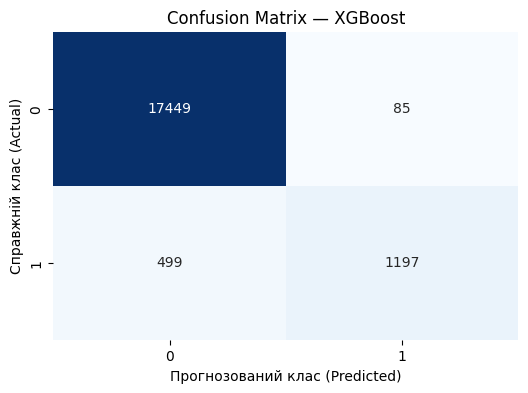



Модель: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.95      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



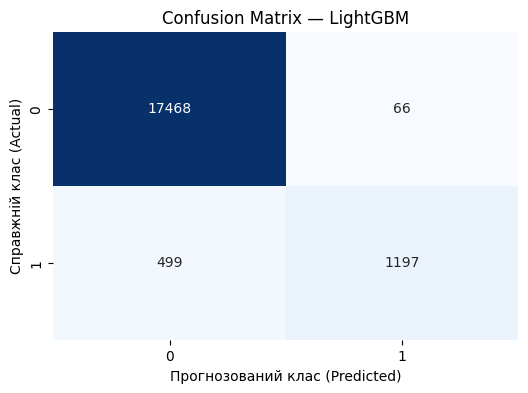



Модель: CatBoost

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.93      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



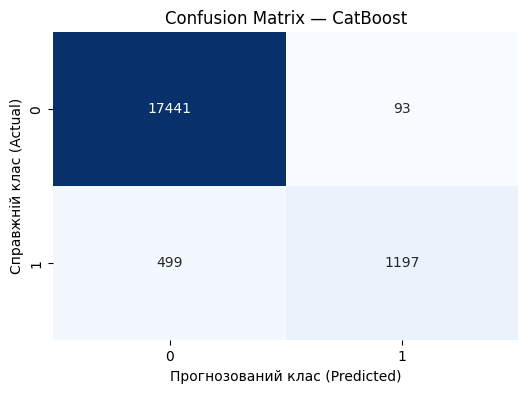

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# 1. Ініціалізація моделей бустингу
boosting_models = {
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0)
}

# 2. Навчання та оцінка кожної моделі на збалансованих даних (SMOTE)
for name, model in boosting_models.items():
    print("=" * 60)
    print(f"Модель: {name}")
    print("=" * 60)

    # Навчаємо на збалансованій масштабованій вибірці
    model.fit(X_train_resampled, y_train_resampled)

    # Прогноз на масштабованій тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # Виведення classification_report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Побудова confusion matrix (теплова карта)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix — {name}')
    plt.xlabel('Прогнозований клас (Predicted)')
    plt.ylabel('Справжній клас (Actual)')
    plt.show()
    print("\n")